### Goals
- In the router, we invoked the model and if it choose to call a tool, we returned a *ToolMessage* to the user
- But what if we simply pass that *ToolMessage* back to the model?
- The is the intuition behind ReAct, a general agent architecture 
  - act - let the model call specific tools 
  - observe - pass the tool output back to the model 
  - reason - let the model reason about the tool output to decide waht to do next(e.g call another tool or just respond directly)
- This general purpose architecture can be applied to many types of tools 
    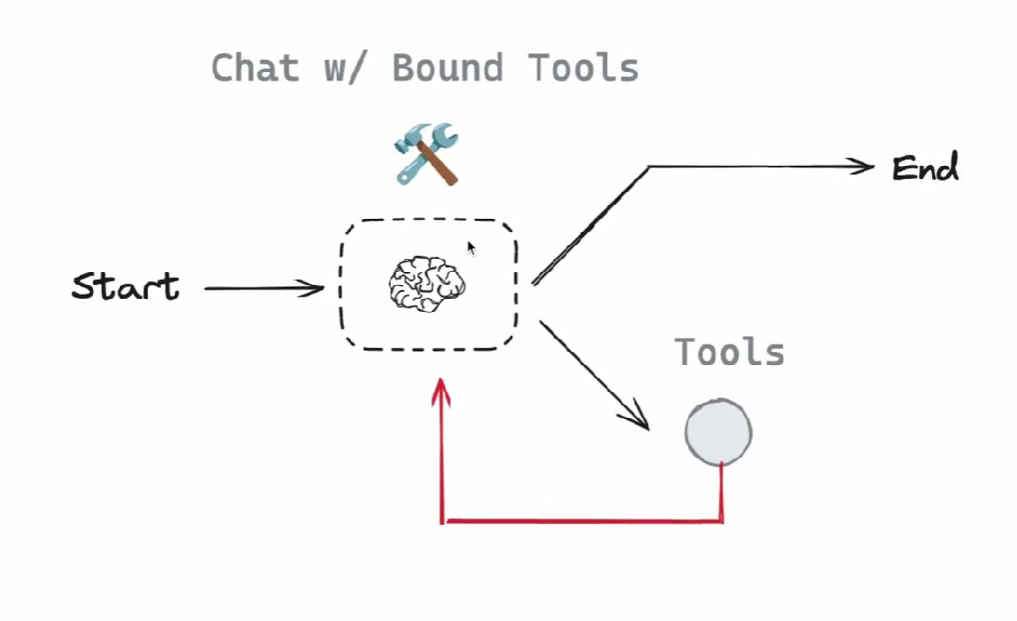

In [ ]:
import os
import sys

# INFO to add the root director to the  system path  and this is only needed for notebooks
sys.path.append(os.path.abspath(os.path.join("..")))
from IPython.display import Image, display
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition

from utils.model import Models


In [ ]:
model = Models()
llm = model.create_groq_model()

In [ ]:
def addition(a: int, b: int) -> int:
    """
    Add the two integer arguments and return the result
    Args :
      a:first integer
      b:second integer
    """
    return a + b


def subtract(a: int, b: int) -> int:
    """
    Subtract  the  smallest from the largest among two integer arguments and return the result
    Args :
      a:first integer
      b:second integer
    """
    return a - b


def mutiply(a: int, b: int) -> int:
    """
    mutiply two integer arguments and return the result
    Args :
      a:first integer
      b:second integer
    """
    return a * b


In [ ]:
tools = [addition, subtract, mutiply]
llm_with_tools = llm.bind_tools(tools)

In [ ]:
sys_msg = SystemMessage(
    content="You are an helpful assistant tasked to do arthmetic operations on the given inputs "
)


def assistant(state: MessagesState):
    return {"messages": [llm_with_tools.invoke([sys_msg] + state["messages"])]}

In [ ]:
builder = StateGraph(MessagesState)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)
builder.add_edge("tools", "assistant")
builder.add_edge("tools", END)
graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
input_msg = HumanMessage(
    content="subtract 3 and 5, then add 9 and finally mutiply 2 to the result "
)

messages = graph.invoke({"messages": [input_msg]})


In [ ]:
for m in messages["messages"]:
    m.pretty_print()